In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '2_train_clean2.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_val_fe.parquet')

from sklearn import set_config
set_config(display='text')
# scikit-learn의 HTML 출력 과정에서 발생한 cp949 간 UTF-8 충돌 때문에 넣는 코드

In [2]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

target_col = 'target_maxrise_6h'  # 모델링 학습부터는 반드시 빼내야 함

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)}, 
    환경변수: {len(env_cols)}, 
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)}, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9, 
    환경변수: 7, 
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [3]:
# ============================================================
# 2. 종속변수 설정
# ============================================================

y_train = train[target_col]
y_val = val[target_col]

In [4]:
# ============================================================
# 3. station_id 원핫인코딩 독립변수 생성
# ============================================================

# OHE 전 독립변수 데이터셋
X_train_fe = train[num_cols_fe]
X_val_fe = val[num_cols_fe]

# 원핫인코딩
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(
    handle_unknown='ignore',  # train에 없던 범주가 나와도 에러 X
    sparse_output=True  # sparse: 희소한, 희소행렬(0이 아닌 값이 드문 행렬)
    # 원핫인코딩 결과를 전체 다 저장 X, 희소한 1의 값의 위치만 저장(메모리 사용 적음)
)

# 학습은 train만
ohe.fit(train[['station_id']])  # sklearn 인코더는 2차원 행렬을 받는다.

# 변환
train_st_id_ohe = ohe.transform(train[['station_id']])
val_st_id_ohe = ohe.transform(val[['station_id']])
# 여기까지는 일반적은 인코딩 과정

# train, val 셋에 합치기
from scipy.sparse import hstack
# scipy안에 희소행렬을 다루는 서브캐키지 scipy.sparse
# hstack(horizontal stack)은 concat(axis=1)과 같은 역할, df가 아닌 행렬도 붙일 수 있는 함수

X_train_with_station_fe = hstack([
    X_train_fe,
    train_st_id_ohe
]).tocsr()  # df + 희소행력(ohe) -> csr형태로 저장하여 sparse 상태 유지
# 이 변수는 더이상 df가 아님

X_val_with_station_fe = hstack([
    X_val_fe,
    val_st_id_ohe
]).tocsr()

print("원핫인코딩 전 후 데이터셋 크기 비교: 행은 같고 열만 들어남")
print(X_train_fe.shape, X_train_with_station_fe.shape)
print(X_val_fe.shape, X_val_with_station_fe.shape)
# 제공된 데이터셋의 관측소 개수는 465개(md파일에 명시)
# 기존컬럼 31개 + 465 = 496이 정상

원핫인코딩 전 후 데이터셋 크기 비교: 행은 같고 열만 들어남
(616299, 31) (616299, 496)
(133325, 31) (133325, 496)


In [5]:
import os
print('CPU 논리 프로세서 수: ', os.cpu_count())

# 배깅 트리모델은 연산량이 많아 병렬처리 필요
# 모델 함수 내 n_jobs = 병렬연산 CPU 허용 수

CPU 논리 프로세서 수:  6


In [ ]:
# ============================================================
# 4. 모델12, 23: RF, EtraTrees 경량화 모델
# ============================================================
# RF와 ET 기본설정으로 돌렸더니 8시간 이후에도 멈추지 않음
# hp조절, 경량화해서 구동

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest': RandomForestRegressor(
        n_estimators=30,
        max_depth=12,
        max_features=0.3,
        min_samples_leaf=10,
        n_jobs=2,
        verbose=10,
        random_state=42
    ),

    'ExtraTrees': ExtraTreesRegressor(
        n_estimators=30,
        max_depth=12,
        max_features=0.3,
        min_samples_leaf=10,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

# 학습, 예측, 평가
preds_bag = {}  # 모델돌리는 셀과 정리하는 셀을 분리, 그러려면 결과들을 변수로 저장해야함
results_bag = {}

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 2 of 30
building tree 1 of 30
building tree 3 of 30
building tree 4 of 30


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    9.3s


building tree 5 of 30
building tree 6 of 30


[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:   20.5s


...

[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:   25.9s


building tree 17 of 30
building tree 18 of 30
building tree 19 of 30
building tree 20 of 30
building tree 21 of 30
building tree 22 of 30
building tree 23 of 30


[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:   40.2s


building tree 24 of 30
building tree 25 of 30
building tree 26 of 30
building tree 27 of 30
building tree 28 of 30
building tree 29 of 30
building tree 30 of 30


[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:   56.9s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:    0.2s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    0.9s
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:    1.2s finished


In [ ]:
# ============================================================
# 6. 모델 12-2 RF 다시 조금 무겁게(RMSE 개선목적)
# ============================================================

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest_2': RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        max_features=0.5,
        min_samples_leaf=3,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

# 학습, 예측, 평가

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 2 of 100
building tree 1 of 100
building tree 3 of 100


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:   50.0s


building tree 4 of 100
building tree 5 of 100
building tree 6 of 100


[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:  1.9min


...

[Parallel(n_jobs=2)]: Done  81 tasks      | elapsed: 37.7min


building tree 84 of 100
building tree 85 of 100
building tree 86 of 100
building tree 87 of 100
building tree 88 of 100
building tree 89 of 100
building tree 90 of 100
building tree 91 of 100
building tree 92 of 100
building tree 93 of 100
building tree 94 of 100
building tree 95 of 100
building tree 96 of 100


[Parallel(n_jobs=2)]: Done  94 tasks      | elapsed: 43.7min


building tree 97 of 100
building tree 98 of 100
building tree 99 of 100
building tree 100 of 100


[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed: 46.5min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done  28 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:    0.6s
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.7s
[Parallel(n_jobs=2)]: Done  57 tasks      | elapsed:    0.9s
[Parallel(n_jobs=2)]: Done  68 tasks      | elapsed:    1.1s
[Parallel(n_jobs=2)]: Done  81 tasks      | elapsed:    1.4s
[Parallel(n_jobs=2)]: Done  94 tasks      | elapsed:    1.6s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.7s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBac

In [ ]:
# ============================================================
# 4. 모델12-3 RF 다시 조금 가볍게(n_estimators 100 -> 30)
# ============================================================

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest_3': RandomForestRegressor(
        n_estimators=30,
        max_depth=20,
        max_features=0.5,
        min_samples_leaf=3,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 2 of 30building tree 1 of 30

building tree 3 of 30


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:   49.4s


building tree 4 of 30
building tree 5 of 30
building tree 6 of 30


[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:  1.9min


...

[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:  6.5min


building tree 17 of 30
building tree 18 of 30
building tree 19 of 30
building tree 20 of 30
building tree 21 of 30
building tree 22 of 30
building tree 23 of 30


[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed: 10.1min


building tree 24 of 30
building tree 25 of 30
building tree 26 of 30
building tree 27 of 30
building tree 28 of 30
building tree 29 of 30
building tree 30 of 30


[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed: 13.8min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:    0.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    0.7s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    1.6s
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:    2.2s finished


In [ ]:
# ============================================================
# 4. 모델12-4 RF4 (n_estimators 30 고정, min_samples_leaf: 3 -> 10)
# ============================================================
# n_estimators 100 -> 30에서 구동시간은 감소, train 과적합은 그대로
# train 과적합 저감을 위해

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest_4': RandomForestRegressor(
        n_estimators=30,
        max_depth=20,
        max_features=0.5,
        min_samples_leaf=10,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }


In [ ]:
# ============================================================
# 4. 모델12-5 RF5 (min_samples_leaf: 3 -> 10 -> 5)
# ============================================================
# train 과적합 저감을 위한 min_samples_leaf를 10으로 올렸더니 복잡도 감소, 과적합 개선
# Val_RMSE도 같이 떨어져 중간값으로 다시 실험

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest_5': RandomForestRegressor(
        n_estimators=30,
        max_depth=20,
        max_features=0.5,
        min_samples_leaf=5,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }


In [ ]:
# ============================================================
# 4. 모델12-6 RF6 (min_samples_leaf = 10, max_depth = 20 -> 15)
# ============================================================
# train 과적합 저감을 위한 min_samples_leaf를 10으로 올렸더니 복잡도 감소, 과적합 개선
# train_RMSE도 같이 떨어져 중간값으로 다시 실험

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest_6': RandomForestRegressor(
        n_estimators=30,
        max_depth=15,
        max_features=0.5,
        min_samples_leaf=10,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }


In [ ]:
# ============================================================
# 4. 모델12-7 RF7 (max_depth = 20 -> 15 -> 18)
# ============================================================
# max_depth 15는 train > val로 역전
# Val_RMSE도 같이 많이 올라가는 트레이드오프

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest_7': RandomForestRegressor(
        n_estimators=30,
        max_depth=18,
        max_features=0.5,
        min_samples_leaf=10,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }

In [24]:
# ============================================================
# 4. 모델12-8 RF8 (max_depth = 20, max_feature = 0.5 -> 0.3
# ============================================================
# max_depth는 낮추면 val_RASE 상승이 확연, 유지하는 것이 타당
# max_feature를 더 낮게 제한하여 과적합 개선 시도

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

# 모델 정의
models_bag = {
    'RandomForest_8': RandomForestRegressor(
        n_estimators=30,
        max_depth=20,
        max_features=0.3,
        min_samples_leaf=10,
        n_jobs=2,
        verbose=10,
        random_state=42
    )
}

for name, model in models_bag.items():

    start = time.time()

    # 학습
    model.fit(
        X_train_with_station_fe,
        y_train
    )

    # 예측
    pred = model.predict(X_val_with_station_fe)
    pred_train = model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


building tree 1 of 30
building tree 2 of 30
building tree 3 of 30


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:   28.1s


building tree 4 of 30
building tree 5 of 30
building tree 6 of 30


[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:  1.1min


...

[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:  3.6min


building tree 17 of 30
building tree 18 of 30
building tree 19 of 30
building tree 20 of 30
building tree 21 of 30
building tree 22 of 30
building tree 23 of 30


[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:  5.4min


building tree 24 of 30
building tree 25 of 30
building tree 26 of 30
building tree 27 of 30
building tree 28 of 30
building tree 29 of 30
building tree 30 of 30


[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:  7.5min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:    0.4s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:    0.7s
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    1.0s
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:    1.6s
[Parallel(n_jobs=2)]: Done  30 out of  30 | elapsed:    2.3s finished


In [25]:
# rmse 비교표 만들기
result_df = pd.DataFrame.from_dict(
    results_bag,
    orient='index',  # orient: orientation, 방향이라는 의미
    # 바깥 딕셔너리 키를 행인덱스로 보냄, 내부 딕셔너리 키는 자동으로 열인덱스로
    # 기본값은 orient='columns' 반대로 보냄
    # 그냥 없이 그려보고, 행열바꾸고 싶으면 넣으면 됨
)
print(result_df)
print()


                  RMSE  RMSE_train     Gap   time_oper
RandomForest_3  0.1996      0.1689  0.0307  829.784876
RandomForest_4  0.2001      0.1906  0.0095  681.458192
RandomForest_5  0.1996      0.1769  0.0226  736.536007
RandomForest_6  0.2025      0.2085 -0.0060  366.436239
RandomForest_7  0.2011      0.1967  0.0043  564.769859
RandomForest8   0.2009      0.1958  0.0051  426.985948
RandomForest_8  0.2009      0.1958  0.0051  453.162323



In [ ]:
# RandomForest_8 모델 저장하기
# 저장 해 두면 학습이 필요없어 바로 예측에 들어가므로 매우 빨라짐

# 학습된 모델인지 확인하기
from sklearn.utils.validation import check_is_fitted

check_is_fitted(
    models_bag['RandomForest_8']
) 
# 에러 없으면 학습된 것

# 저장하기
import joblib

joblib.dump(
    models_bag['RandomForest_8'],
    PROJECT_ROOT / 'models' / 'RF_8.joblib'
)

# 불러올때는?
rf8_model = joblib.load(
    PROJECT_ROOT / 'models' / 'RF_8.joblib'
)

In [ ]:
# ============================================================
# 모델 불러오기 시험용
# ============================================================

# 모델 불러오기
import joblib
rf8_model = joblib.load(
    PROJECT_ROOT / 'models' / 'RF_8.joblib'
)

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error

# 모델 구동시간 측정용
import time

results_bag = {}
preds_bag = {}

# 모델 정의
models_bag = {
    'RandomForest_8(loading)': rf8_model
}

for name, model in models_bag.items():

    start = time.time()

    # 학습 불필요
 
    # 예측
    pred = rf8_model.predict(X_val_with_station_fe)
    pred_train = rf8_model.predict(X_train_with_station_fe)

    preds_bag[name] = {  # dict[key] 형태로 저장과 조회가 가능함
        'pred_val': pred,
        'pred_train': pred_train
    }
    # 이중 딕셔너리는 dict[바깥키][안쪽키] 형테로 조회가 가능함

    # RMSE 평가
    rmse = root_mean_squared_error(
        y_val,
        pred
    )
    rmse_train = root_mean_squared_error(
        y_train,
        pred_train
    )

    # 과적합 진단
    gap = rmse - rmse_train

    elapsed = time.time() - start

    results_bag[name] = {
        'RMSE': round(rmse, 4),
        'RMSE_train': round(rmse_train, 4),
        'Gap': round(gap, 4),
        'time_oper' : elapsed
    }
print()

results_df = pd.DataFrame.from_dict(
    results_bag
)
print(results_df)

                           RMSE  RMSE_train     Gap  time_oper
RandomForest_8(loading)  0.2009      0.1958  0.0051    3.21295



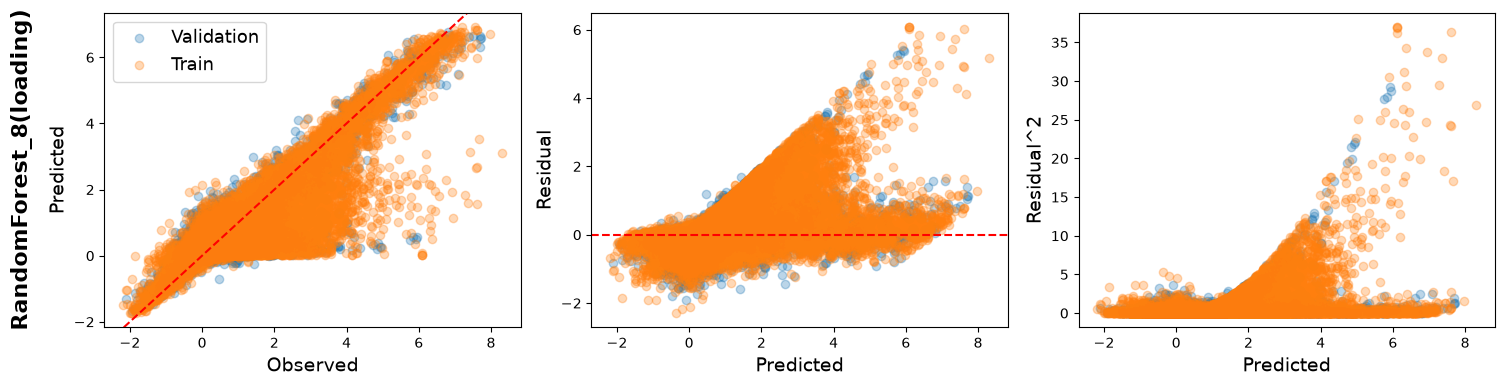

In [17]:
# rmse 비교표 만들기
result_df = pd.DataFrame.from_dict(
    results_bag,
    orient='index',  # orient: orientation, 방향이라는 의미
    # 바깥 딕셔너리 키를 행인덱스로 보냄, 내부 딕셔너리 키는 자동으로 열인덱스로
    # 기본값은 orient='columns' 반대로 보냄
    # 그냥 없이 그려보고, 행열바꾸고 싶으면 넣으면 됨
)
print(result_df)
print()

# 모델별 val, train 예측값 플롯해보기: 각각 산점도, 오차 산점도, 오차제곱 산점도

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(preds_bag),
    3,
    figsize = (15, 4 * len(preds_bag))
)

if len(preds_bag) == 1:
    axes = [axes]

for i, (name, pred) in enumerate(preds_bag.items()):
    # preds.items()는 (외부 키, 내부 키 : 값) 형태임
    # 여기서 name은 외부 키, pred는 내부 딕셔너리 두개씩(pred_val, pred_train)
    # pred를 꺼내서 pred[]형태로 꺼내서 쓸 수 있음

    # 모델명: 각 행의 0열 그래프 왼쪽에 세로 표시
    axes[i][0].text(
        -0.2, 0.5,
        name,
        transform = axes[i][0].transAxes,
        rotation = 90,
        fontsize = 16,
        fontweight = 'bold',
        ha = 'center',
        va = 'center'
    )

    # 잔차 계산
    resid_val = y_val - pred['pred_val']
    resid_train = y_train - pred['pred_train']

    # 1열 그래프: 실제값 vs 예측값
    axes[i][0].scatter(
        y_val,
        pred['pred_val'],
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][0].scatter(
        y_train,
        pred['pred_train'],
        alpha = 0.3,
        label = 'Train'
    )
    axes[i][0].set_xlabel('Observed', fontsize = 14)
    axes[i][0].set_ylabel('Predicted', fontsize = 14)
    # 기준선: y=x
    axes[i][0].axline((0, 0), slope = 1, color = 'red', linestyle = '--')

    # 2열 그래프: 잔차
    axes[i][1].scatter(
        y_val,
        resid_val,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][1].scatter(
        y_train,
        resid_train,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][1].set_xlabel('Predicted', fontsize = 14)
    axes[i][1].set_ylabel('Residual', fontsize = 14)
    # 기준선 y=0
    axes[i][1].axhline(y = 0, color = 'red', linestyle = '--')

    # 3열 그래프: 잔차제곱
    axes[i][2].scatter(
        y_val,
        resid_val ** 2,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][2].scatter(
        y_train,
        resid_train ** 2,
        alpha = 0.3,
        label = 'Validation'
    )
    axes[i][2].set_xlabel('Predicted', fontsize = 14)
    axes[i][2].set_ylabel('Residual^2', fontsize = 14)

    axes[i][0].legend(fontsize = 13)

plt.tight_layout()
plt.show()